🇬🇧 [English](03_modeling.ipynb) · 🇪🇸 [Español](03_modeling_es.ipynb)

# 03 — Modeling (working notebook, importa `src/fraud`)

Corre `src/fraud/pipeline.py::run_train` end-to-end -- el mismo orquestador que usa
`fraud train` en la CLI -- para inspeccionar métricas y la curva de umbral mientras se
ajustan modelos, sin reescribir la lógica de entrenamiento en la notebook.


In [1]:
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

import matplotlib.pyplot as plt
from fraud.data import make_split
from fraud.features import build_features
from fraud.pipeline import run_train
from fraud.threshold import threshold_sweep


In [2]:
model, metrics = run_train(
    PROJECT_ROOT / "data/raw/fraudTrain.csv",
    PROJECT_ROOT / "data/raw/fraudTest.csv",
    model_name="xgboost",
)
metrics


/home/datakrdo/Documents/repos/portfolio/fraud/.venv/lib/python3.14/site-packages/xgboost/core.py:569: UserWarning: [09:10:04] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


{'model': 'xgboost',
 'version': '2026-11-18T12:10:04+00:00-8581d35',
 'prevalence_train': 0.005753176393467908,
 'threshold': 0.03,
 'fp_cost': 4.0,
 'valid': {'prevalence': 0.005930553145545337,
  'pr_auc': 0.9757774438691463,
  'pr_auc_lift': 164.5339684042946,
  'roc_auc': 0.9996106691098008,
  'precision': np.float64(0.684856753069577),
  'recall': np.float64(0.9791937581274383),
  'tn': 257104,
  'fp': 693,
  'fn': 32,
  'tp': 1506},
 'test': {'prevalence': 0.0038598644278853163,
  'pr_auc': 0.9562991693600327,
  'pr_auc_lift': 247.75460051169603,
  'roc_auc': 0.9988532289978889,
  'precision': np.float64(0.6211124401913876),
  'recall': np.float64(0.9682983682983684),
  'tn': 552307,
  'fp': 1267,
  'fn': 68,
  'tp': 2077}}

`metrics` reporta PR-AUC (y su lift sobre prevalencia) en validación y en el holdout
`fraudTest.csv`, con el umbral congelado en validación por `select_threshold_by_savings`.
Son los mismos números que produce `uv run fraud train ... && uv run fraud evaluate ...`.


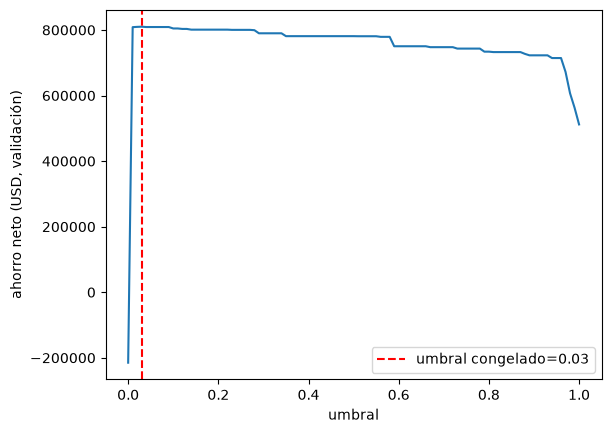

In [3]:
data_split = make_split(PROJECT_ROOT / "data/raw/fraudTrain.csv", PROJECT_ROOT / "data/raw/fraudTest.csv")
valid_feat = build_features(data_split.valid, history=data_split.train)
valid_proba = model.predict_proba(data_split.valid, history=data_split.train)
sweep = threshold_sweep(valid_feat["is_fraud"], valid_proba, valid_feat["amt"])

fig, ax = plt.subplots()
ax.plot(sweep["threshold"], sweep["net_savings_usd"])
ax.axvline(model.threshold, color="red", linestyle="--", label=f"umbral congelado={model.threshold:.2f}")
ax.set_xlabel("umbral")
ax.set_ylabel("ahorro neto (USD, validación)")
ax.legend()
plt.show()


Curva de ahorro neto sobre validación, con el umbral realmente congelado por
`run_train` marcado en rojo -- confirma visualmente que el máximo de la curva y el
umbral guardado en el artefacto coinciden. Detalle e interpretación completa del
trade-off en la sección 10 de `fraud-portfolio_es.ipynb`.
